In [2]:
import pandas as pd
from db_queries import get_location_metadata
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from tqdm import tqdm
import numpy as np
from matplotlib.ticker import MaxNLocator
from pathlib import Path
import yaml

# Set paths ####################################################################
RAW_DATA_PATH = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/training_data/2026_09_13.01/data.parquet"
GBD_FILE = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/input/gbd_prevalence/gbd_mean_neonatal_mortality_prevalence.parquet"
INFERENCE_FILE_09_14 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/results/2026_09_14.01/ssp245.parquet"  # Consumption merged on birth year
RESULTS_09_14 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/models/2026_09_14.02/"  # .01 is the input spec; .02 is the fit

# RESULTS_09_21 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/models/2026_09_21.02/"
# RESULTS_09_22 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/models/2026_09_22.02/"
# RESULTS_09_23 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/models/2026_09_23.02/"  # birth_year dropped, consumption_median_RT rescaled to $/day
# RESULTS_09_24 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/models/2026_09_23.03/"  # birth_year dropped, consumption_median_RT, climate variables included
RESULTS_09_25 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/models/2026_09_25.01/"  # final specification, sex_id modified
RESULTS_09_28 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/models/2026_09_25.01/"  # final specification, sex_id modified


# INFERENCE_FILE_09_21 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/results/2026_09_22.01/ssp245.parquet"  # Inclusion of consumption_pd_national_median (logged)
# INFERENCE_FILE_09_22 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/results/2026_09_22.02/ssp245.parquet"  # Inclusion of consumption_pd_national_median (logged)
# INFERENCE_FILE_09_23 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/results/2026_09_23.01/ssp245.parquet"  # model 2026_09_23.02: consumption_median_RT (LDI based), no birth_year
# INFERENCE_FILE_09_24 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/results/2026_09_23.02/ssp245.parquet"  # model 2026_09_24: birth_year dropped, consumption_median_RT, climate variables included
INFERENCE_FILE_09_25 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/results/2026_09_25.02/ssp245.parquet"  # final specification, sex_id modified
INFERENCE_FILE_09_28 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/results/2026_09_28.01/ssp245.parquet"  # final specification, sex_id modified

PLOT_OUTPUT = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/plots/"


df_raw = pd.read_parquet(RAW_DATA_PATH)

# Add location names
locs = get_location_metadata(location_set_id=39, release_id=16)

df_raw = df_raw.merge(
    locs[["location_id", "location_name", "level", "super_region_name"]],
    on="location_id",
    how="left",
)

df_raw.head()

,year_start,year_end,nid,survey_name,int_year,int_month,sex_id,mothers_age_year,aod_months,age_month,...,year_id,age_group_id,int_birth_year_diff_months,log_consumption_pd,sdi,consumption_pd_national_median,consumption_median_RT,location_name,level,super_region_name
0,2009,2010,13109,DHS_MIS,None,None,2,None,0,0,...,2009,42,0,-0.245692,0.318291,2.179549,2.361256,Uganda,3,Sub-Saharan Africa
1,2022,2022,538795,None,2022,5,2,18,0,0,...,2021,42,11,1.312609,0.447416,3.220460,3.404259,United Republic of Tanzania,3,Sub-Saharan Africa
2,2017,2017,353526,None,2017,4,1,20,0,0,...,2017,42,0,2.448691,0.373539,3.087602,4.210878,Senegal,3,Sub-Saharan Africa
3,2019,2021,467681,DHS,None,None,1,None,0,0,...,2020,42,2,1.619791,0.583046,4.671741,5.111802,India,3,South Asia
4,2000,2000,19156,None,2000,2,2,24,0,0,...,1999,42,2,-0.227447,0.340183,1.772798,2.106530,Cambodia,3,"Southeast Asia, East Asia, and Oceania"


60 countries have a fitted random intercept in 2026_09_25.01
survey points: 49 country-years with >= 100 births (Angola, Namibia, Rwanda)
Saved /mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/plots/predictions_09_29_four_countries.pdf


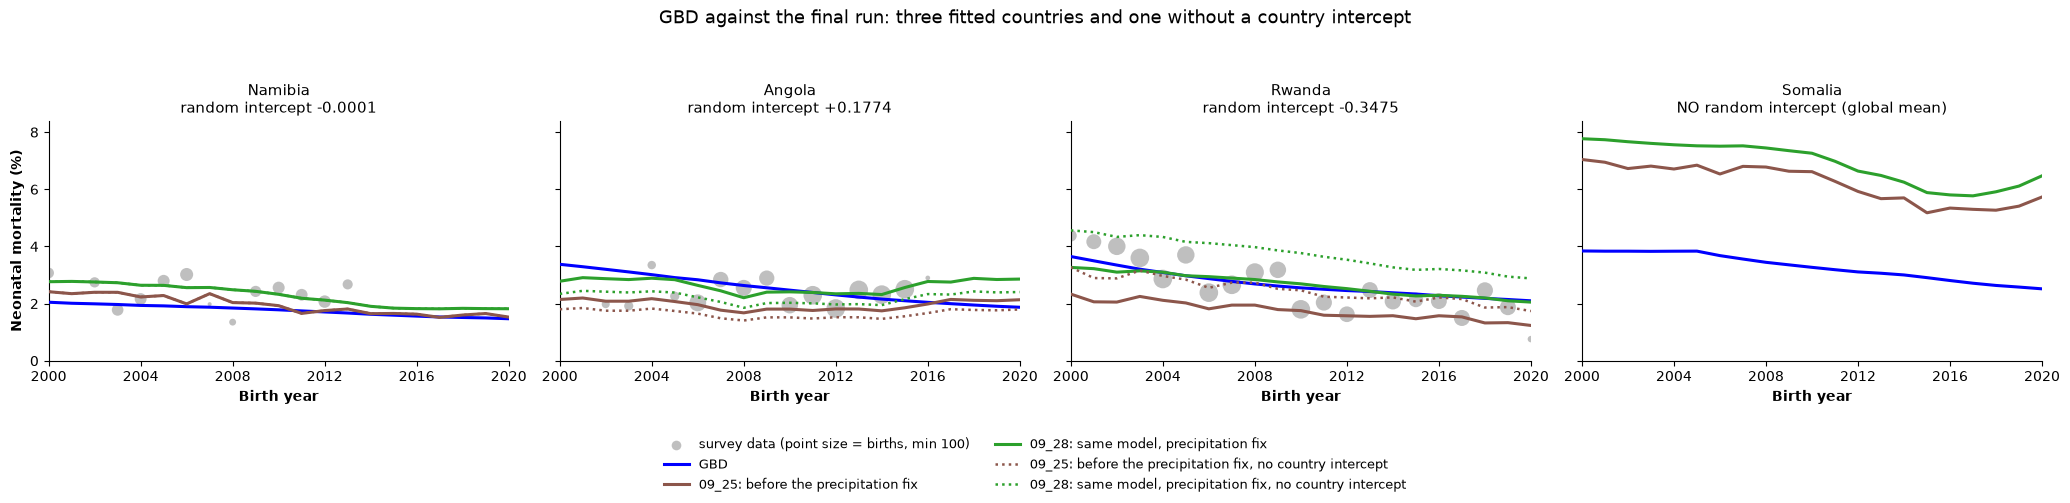


2000 -> 2020 (%):
               gbd_first  gbd_last  i0925_first  i0925_last  i0928_first  i0928_last  i0925_no_re_first  i0925_no_re_last  i0928_no_re_first  i0928_no_re_last
location_name                                                                                                                                                 
Namibia             2.05      1.47         2.42        1.53         2.77        1.82               2.42              1.53               2.77              1.82
Angola              3.38      1.87         2.14        2.14         2.78        2.86               1.80              1.79               2.34              2.41
Rwanda              3.65      2.10         2.33        1.24         3.27        2.05               3.27              1.74               4.56              2.88
Somalia             3.84      2.52         7.04        5.73         7.77        6.47               7.04              5.73               7.77              6.47


In [3]:
# GBD against the final run, three focus countries plus one without a ranef ##
# Same shape as predictions_four_runs_three_countries, cut down to two series:
# GBD and the 2026_09_25.01 fit. Both are sex-averaged, and the inference run
# is averaged over draws.
#
# The fourth panel is the point of the figure. Somalia is Sub-Saharan African
# and appears in the results, but it has no DHS survey in the training data, so
# the model never fitted it a country intercept. Its prediction is the global
# fixed intercept plus covariates, while the other three carry their own
# offset. Each panel says which it is, read from the fit rather than hardcoded.
from scipy.special import expit, logit

R5_COUNTRIES = ["Namibia", "Angola", "Rwanda", "Somalia"]
R5_YEARS = (2000, 2020)
R5_SERIES = {
    "gbd": (GBD_FILE, False, "blue", "GBD"),
    "i0925": (
        INFERENCE_FILE_09_25,
        True,
        "#8c564b",
        "09_25: before the precipitation fix",
    ),
    "i0928": (
        INFERENCE_FILE_09_28,
        True,
        "#2ca02c",
        "09_28: same model, precipitation fix",
    ),
}
R5_RANEF = Path(RESULTS_09_25) / "base_model_ranef.parquet"


def _r5_mean_draw(frame):
    """Inference files carry either draw columns or a long `draw` column."""
    draw_cols = [c for c in frame.columns if c.startswith("draw_")]
    if draw_cols:
        out = frame[[c for c in frame.columns if "draw_" not in c]].copy()
        out["prevalence"] = frame[draw_cols].mean(axis=1)
        return out
    value_col = "value" if "value" in frame.columns else "prevalence"
    keys = [c for c in ("location_id", "year_id", "sex_id") if c in frame.columns]
    return (
        frame.groupby(keys, as_index=False)[value_col]
        .mean()
        .rename(columns={value_col: "prevalence"})
    )


_r5_key = ["location_id", "year_id", "sex_id"]
r5 = None
for col, (path, is_draws, _c, _l) in R5_SERIES.items():
    f = pd.read_parquet(path).reset_index()
    f = (
        _r5_mean_draw(f).rename(columns={"prevalence": col})
        if is_draws
        else f.rename(columns={"gbd_mean_prevalence": col})
    )
    keys = [k for k in _r5_key if k in f.columns]
    f = f[keys + [col]]
    r5 = f if r5 is None else r5.merge(f, on=keys, how="inner")

r5 = (
    r5.merge(
        locs[["location_id", "location_name", "ihme_loc_id"]].drop_duplicates(
            "location_id"
        ),
        on="location_id",
        how="inner",
    )
    .query("year_id >= @R5_YEARS[0] and year_id <= @R5_YEARS[1]")
    .groupby(["location_name", "ihme_loc_id", "year_id"], as_index=False)[
        list(R5_SERIES)
    ]
    .mean()
    .sort_values("year_id")
)

# Which of these countries the model actually fitted an intercept for.
_ranef = pd.read_parquet(R5_RANEF)["offset"]
print(
    f"{_ranef.shape[0]} countries have a fitted random intercept in "
    f"{Path(RESULTS_09_25).name}"
)

# The same prediction with the country intercept taken back out. The published
# value is a mean of expit() over ten income deciles, so subtracting the offset
# from a single aggregate logit is an approximation rather than a re-run of the
# decile integration. Checked against the exact integration using this model's
# own per-decile spline effects: the two agree to within 0.03% relative for
# these countries, which is far below the effect being drawn.
R5_NO_RE = [c for c in R5_SERIES if c != "gbd"]
# A subnational location has no intercept of its own - it inherits its
# country's, because the raster is burned from the national polygon. The
# ihme_loc_id prefix before "_" is that country ("IND_4841" -> "IND"); a
# level-3 code is already its own country, so this is a no-op for them.
_off = r5["ihme_loc_id"].str.split("_").str[0].map(_ranef).fillna(0.0)
for _c in R5_NO_RE:
    r5[f"{_c}_no_re"] = expit(logit(r5[_c].clip(1e-9, 1 - 1e-9)) - _off)

# Observed survey rates behind the lines: mean neonatal_mortality by country
# and birth year, straight from the training data. Years with very few births
# are dropped rather than drawn small - Namibia has a birth year with n=4 and a
# 25% rate, which is noise but would still set the shared y limit.
R5_MIN_BIRTHS = 100
r5_obs = (
    df_raw[df_raw["location_name"].isin(R5_COUNTRIES)]
    .groupby(["location_name", "birth_year"], observed=True)
    .agg(rate=("neonatal_mortality", "mean"), n=("neonatal_mortality", "size"))
    .reset_index()
    .query(
        "n >= @R5_MIN_BIRTHS and birth_year >= @R5_YEARS[0] "
        "and birth_year <= @R5_YEARS[1]"
    )
)
print(
    f"survey points: {len(r5_obs)} country-years with >= {R5_MIN_BIRTHS} births "
    f"({', '.join(sorted(r5_obs['location_name'].unique()))})"
)

_r5_focus = r5[r5["location_name"].isin(R5_COUNTRIES)]
R5_YMAX = (
    100
    * float(
        max(
            _r5_focus[[*R5_SERIES, *(f"{c}_no_re" for c in R5_NO_RE)]].to_numpy().max(),
            r5_obs["rate"].max(),
        )
    )
    * 1.08
)

fig, axes = plt.subplots(
    ncols=len(R5_COUNTRIES), figsize=(5.2 * len(R5_COUNTRIES), 5.0), sharey=True
)
axes = np.atleast_1d(axes)
handles, labels = [], []
for ax, country in zip(axes, R5_COUNTRIES):
    block = r5[r5["location_name"] == country].sort_values("year_id")
    loc = block["ihme_loc_id"].iloc[0]
    obs = r5_obs[r5_obs["location_name"] == country]
    if len(obs):
        ax.scatter(
            obs["birth_year"],
            100 * obs["rate"],
            s=np.clip(obs["n"] / 12, 8, 180),
            color="0.55",
            alpha=0.55,
            linewidths=0,
            zorder=1,
            label=f"survey data (point size = births, min {R5_MIN_BIRTHS})",
        )
    for col, (_p, _d, colour, label) in R5_SERIES.items():
        ax.plot(
            block["year_id"],
            100 * block[col],
            color=colour,
            lw=2.2,
            zorder=3,
            label=label,
        )
    # Dotted: the same run with this country's intercept removed. Drawn only
    # where there is one to remove, so Somalia's single line is unambiguous.
    if loc in _ranef.index:
        for _c in R5_NO_RE:
            ax.plot(
                block["year_id"],
                100 * block[f"{_c}_no_re"],
                color=R5_SERIES[_c][2],
                lw=1.8,
                ls=":",
                zorder=4,
                label=f"{R5_SERIES[_c][3]}, no country intercept",
            )
    ax.set_xlim(*R5_YEARS)
    ax.set_ylim(0, R5_YMAX)
    ax.xaxis.set_major_locator(MaxNLocator(6, integer=True))
    ax.set_xlabel("Birth year", fontweight="bold")
    note = (
        f"random intercept {_ranef[loc]:+.4f}"
        if loc in _ranef.index
        else "NO random intercept (global mean)"
    )
    ax.set_title(f"{country}\n{note}", fontsize=10.5)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    if not handles:
        handles, labels = ax.get_legend_handles_labels()
axes[0].set_ylabel("Neonatal mortality (%)", fontweight="bold")
fig.legend(handles, labels, loc="lower center", ncol=2, fontsize=9, frameon=False)
fig.suptitle(
    "GBD against the final run: three fitted countries and one without a "
    "country intercept",
    fontsize=13,
)
fig.tight_layout(rect=(0, 0.16, 1, 0.93))
plot_path = f"{PLOT_OUTPUT}predictions_09_29_four_countries.pdf"
fig.savefig(plot_path, bbox_inches="tight")
print(f"Saved {plot_path}")
plt.show()

print(f"\n{R5_YEARS[0]} -> {R5_YEARS[1]} (%):")
_ends = (
    _r5_focus.groupby("location_name")
    .agg(
        **{
            f"{c}_{w}": (c, w)
            for c in [*R5_SERIES, *(f"{c}_no_re" for c in R5_NO_RE)]
            for w in ("first", "last")
        }
    )
    .loc[R5_COUNTRIES]
)
print((100 * _ends).round(2).to_string())

In [ ]:
# Every location in the results, level 3 and subnational, straight to pdf ####
# Same encoding as predictions_09_29_four_countries:
#   colour    = run       (blue GBD, brown 09_25, green 09_28)
#   solid     = with the country random intercept
#   dotted    = the same run with that intercept removed
#   grey dots = observed survey rates, sized by births
#
# Inference writes only most-detailed locations, so 11 countries never appear
# as a national row - they exist purely as their 280 subnational units. Those
# get their own pages, headed by the country, rather than being scattered
# through the regional pages or dropped. Everything else is grouped by region.
#
# The dotted lines matter most on the subnational pages: a subnational unit has
# no intercept of its own, it inherits its COUNTRY's. The raster is burned from
# the national polygon, so every pixel inside India carries IND's +0.3495 and
# all 31 states get the identical offset. The gap between solid and dotted is
# therefore the same in every panel of an Indian page - that constant gap is
# the point.
R6_PER_PAGE = (3, 3)
R6_PATH = f"{PLOT_OUTPUT}predictions_09_29_all_countries.pdf"

_meta = locs[
    ["location_id", "ihme_loc_id", "location_name", "level", "parent_id", "region_name"]
].drop_duplicates("location_id")
_pname = _meta.set_index("location_id")["location_name"]

r6 = r5.merge(
    _meta.drop(columns=["location_id", "location_name"]).drop_duplicates("ihme_loc_id"),
    on="ihme_loc_id",
    how="left",
)
# "IND_4841" -> "IND"; a level-3 code is already its own country
r6["ranef_iso"] = r6["ihme_loc_id"].str.split("_").str[0]
# page group: the region for a country, the parent country for a subnational
r6["page_group"] = np.where(
    r6["level"] >= 4,
    r6["parent_id"].map(_pname) + "  —  subnational units",
    r6["region_name"],
)

r6_obs = (
    df_raw.groupby(["ihme_loc_id", "birth_year"], observed=True)
    .agg(rate=("neonatal_mortality", "mean"), n=("neonatal_mortality", "size"))
    .reset_index()
    .query(
        "n >= @R5_MIN_BIRTHS and birth_year >= @R5_YEARS[0] "
        "and birth_year <= @R5_YEARS[1]"
    )
)
# ihme_loc_id -> country name, for labelling inherited survey data
_iso_name = (
    locs.query("level == 3")
    .drop_duplicates("ihme_loc_id")
    .set_index("ihme_loc_id")["location_name"]
)

_per_loc = r6.drop_duplicates("ihme_loc_id")
print(
    f"{len(_per_loc)} locations "
    f"({(_per_loc.level == 3).sum()} countries + {(_per_loc.level >= 4).sum()} "
    f"subnational), {r6['page_group'].nunique()} page groups; "
    f"{_per_loc['ranef_iso'].isin(_ranef.index).sum()} carry or inherit a "
    "country random intercept"
)

# regions first, then the subnational country sections
_groups = sorted(
    r6["page_group"].dropna().unique(), key=lambda g: ("￿" in g, "subnational" in g, g)
)
_nrow, _ncol = R6_PER_PAGE
_per_page = _nrow * _ncol
_pages = 0
with PdfPages(R6_PATH) as pdf:
    for group in _groups:
        block = r6[r6["page_group"] == group]
        # Four names are ambiguous across the 473 locations - Georgia,
        # Niger, Punjab and Distrito Federal each name two different places -
        # so panels are keyed on ihme_loc_id and named only for display.
        places = (
            block[["ihme_loc_id", "location_name"]]
            .drop_duplicates()
            .sort_values("location_name")["ihme_loc_id"]
            .tolist()
        )
        for start in range(0, len(places), _per_page):
            chunk = places[start : start + _per_page]
            # Size the grid to what is on the page: 4 panels get 2 rows, not 3.
            # A page with three or fewer panels is stacked in a single column
            # instead - Andean Latin America has three countries, and laying
            # them in one row across a 15-inch page stretches each into an
            # unreadable letterbox.
            _cols = 1 if len(chunk) <= _ncol else _ncol
            _rows = -(-len(chunk) // _cols)
            # Height is built up from fixed parts rather than scaled: the
            # panels get a constant height each, and the page title and legend
            # get their own strips on top. Scaling the strips as a fraction of
            # the figure made a one-panel page give 44% of itself to the legend
            # and collide the page title with the panel title.
            _fw = 7.2 if _cols == 1 else 5.2 * _cols
            _panel_h = 3.4 if _cols == 1 else 4.4
            _legend_in = 1.5 if _cols == 1 else 1.1
            _title_in = 0.9
            _fh = _panel_h * _rows + _legend_in + _title_in
            fig, axes = plt.subplots(_rows, _cols, figsize=(_fw, _fh), squeeze=False)
            axes = axes.ravel()
            handles, labels = [], []
            for ax, place in zip(axes, chunk):
                panel = block[block["ihme_loc_id"] == place].sort_values("year_id")
                iso = panel["ranef_iso"].iloc[0]
                has_re = iso in _ranef.index
                name = panel["location_name"].iloc[0]

                # The training data is coded to country level, so a
                # subnational panel shows its COUNTRY's observed rates. Drawn
                # as open markers there to keep the change of grain visible:
                # the blue GBD line on that panel is the unit's own, the points
                # are national. They are on the panel because the model was
                # fitted to them, and they explain the level it predicts.
                is_sub = panel["level"].iloc[0] >= 4
                obs = r6_obs[r6_obs["ihme_loc_id"] == iso]
                if len(obs):
                    ax.scatter(
                        obs["birth_year"],
                        100 * obs["rate"],
                        s=np.clip(obs["n"] / 25, 5, 90),
                        facecolor="none" if is_sub else "0.55",
                        edgecolor="0.45" if is_sub else "none",
                        linewidths=0.9 if is_sub else 0,
                        alpha=0.75 if is_sub else 0.5,
                        zorder=1,
                        label=(
                            f"{_iso_name.get(iso, iso)} national survey data "
                            f"(size = births)"
                            if is_sub
                            else f"survey data (size = births, min {R5_MIN_BIRTHS})"
                        ),
                    )
                for col, (_p, _d, colour, label) in R5_SERIES.items():
                    ax.plot(
                        panel["year_id"],
                        100 * panel[col],
                        color=colour,
                        lw=1.9,
                        zorder=3,
                        label=label,
                    )
                if has_re:
                    for _c in R5_NO_RE:
                        ax.plot(
                            panel["year_id"],
                            100 * panel[f"{_c}_no_re"],
                            color=R5_SERIES[_c][2],
                            lw=1.5,
                            ls=":",
                            zorder=4,
                            label=f"{R5_SERIES[_c][3]}, no country intercept",
                        )

                ax.set_xlim(*R5_YEARS)
                ax.xaxis.set_major_locator(MaxNLocator(5, integer=True))
                _ycols = [*R5_SERIES] + (
                    [f"{c}_no_re" for c in R5_NO_RE] if has_re else []
                )
                _top = 100 * float(panel[_ycols].to_numpy().max())
                if len(obs):
                    _top = max(_top, 100 * float(obs["rate"].max()))
                ax.set_ylim(0, _top * 1.08)
                ax.set_title(
                    f"{name}\n"
                    + (
                        f"{iso} random intercept {_ranef[iso]:+.4f}"
                        + (" (inherited)" if panel["level"].iloc[0] >= 4 else "")
                        if has_re
                        else "NO random intercept (global mean)"
                    ),
                    fontsize=9,
                )
                ax.tick_params(labelsize=8)
                ax.set_axisbelow(True)
                for side in ("top", "right"):
                    ax.spines[side].set_visible(False)
                if len(handles) < 6:
                    handles, labels = ax.get_legend_handles_labels()
            for ax in axes[len(chunk) :]:
                ax.set_visible(False)
            for ax in axes[: len(chunk)]:
                ax.set_xlabel("Birth year", fontweight="bold", fontsize=9)
            for i in range(0, len(chunk), _cols):
                axes[i].set_ylabel(
                    "Neonatal mortality (%)", fontweight="bold", fontsize=9
                )

            _of = f" ({start // _per_page + 1} of {-(-len(places) // _per_page)})"
            fig.suptitle(
                f"{group}{_of if len(places) > _per_page else ''}",
                fontsize=13,
                y=1 - 0.3 / _fh,
            )
            fig.legend(
                handles,
                labels,
                loc="lower center",
                ncol=1 if _cols == 1 else 2,
                fontsize=8.5,
                frameon=False,
            )
            fig.tight_layout(rect=(0, _legend_in / _fh, 1, 1 - _title_in / _fh))
            pdf.savefig(fig, bbox_inches="tight")
            plt.close(fig)
            _pages += 1

print(f"Saved {R6_PATH} ({_pages} pages)")

473 locations (193 countries + 280 subnational), 32 page groups; 177 carry or inherit a country random intercept
Saved /mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/plots/predictions_09_29_all_countries.pdf (68 pages)


/tmp/ipykernel_1148355/2466233977.py:66: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ).fit()


2026_09_28.01: predicted residual = +1.1845 -6.4773 x SDI (pp);  constant shift +2.217 pp
Saved /mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/plots/rwanda_residual_steps_annotated.pdf


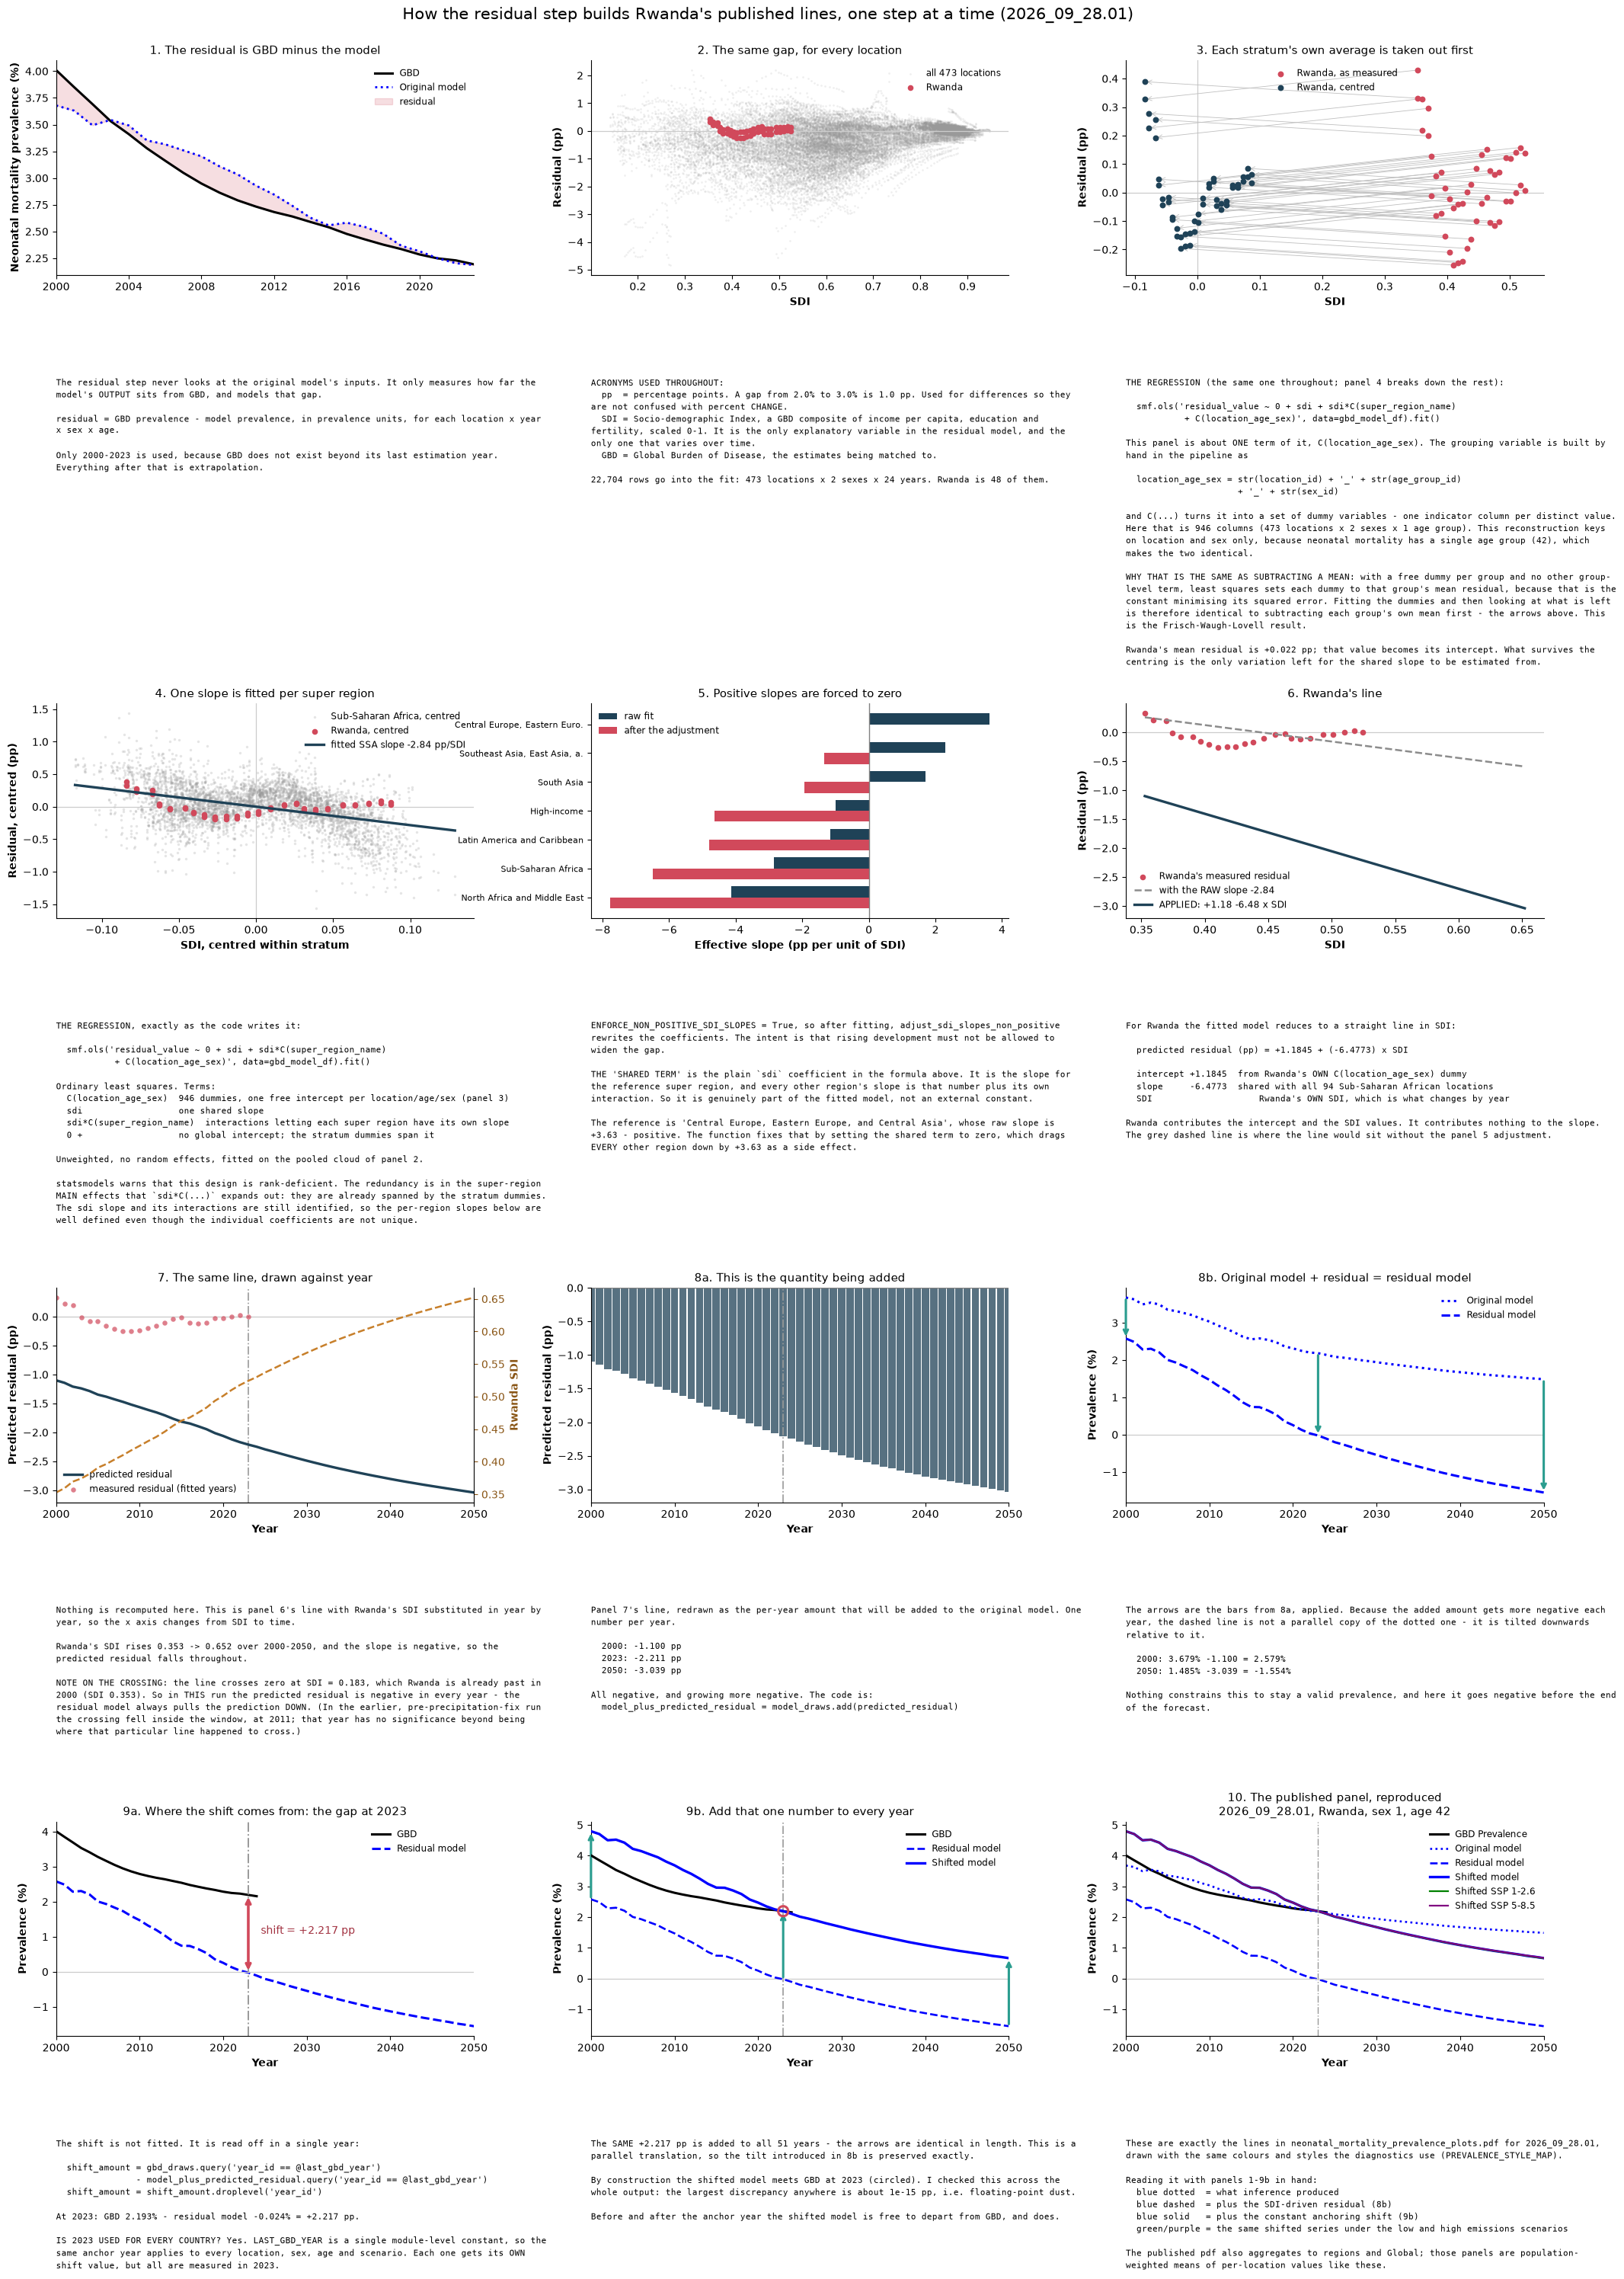

In [ ]:
# The residual step for Rwanda, eleven annotated panels #####################
# Self-contained: everything is read from the residual step's own output for
# results 2026_09_28.01 (model 2026_09_25.01, precipitation fix applied), so
# this does not depend on the inference cells above.
import textwrap

import xarray as xr
import statsmodels.formula.api as smf

ST_RV = "2026_09_28.01"
ST_SEV = f"/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/results/{ST_RV}/sev_means.parquet"
ST_PAST_SDI = "/mnt/share/forecasting/data/32/past/sdi/past_sdi_s130v89/sdi.nc"
ST_FUTURE_SDI = "/mnt/share/forecasting/data/32/future/sdi/future_sdi_s130v89/sdi.nc"
ST_SDI_SCENARIO = 130
ST_LOC, ST_SEX, ST_AGE = 185, 1, 42  # Rwanda, male, 0-6 days
ST_LAST_GBD = 2023  # constants.LAST_GBD_YEAR
ST_SR = "Sub-Saharan Africa"
ST_YEARS = (2000, 2050)


def st_load_sdi():
    past = xr.open_dataset(ST_PAST_SDI).to_dataframe().reset_index()
    past = past.groupby(["location_id", "year_id"], as_index=False)["draws"].mean()
    fut = xr.open_dataset(ST_FUTURE_SDI).to_dataframe().reset_index()
    fut = fut[fut["scenario"] == ST_SDI_SCENARIO]
    fut = fut.groupby(["location_id", "year_id"], as_index=False)["draws"].mean()
    return (
        pd.concat([past, fut])
        .rename(columns={"draws": "sdi"})
        .drop_duplicates(["location_id", "year_id"])
    )


st_sdi = st_load_sdi()
st = (
    pd.read_parquet(ST_SEV)
    .reset_index()
    .query("age_group_id == @ST_AGE")
    .merge(st_sdi, on=["location_id", "year_id"], how="left")
    .merge(
        locs[["location_id", "super_region_name", "location_name"]].drop_duplicates(
            "location_id"
        ),
        on="location_id",
        how="left",
    )
)
st["resid"] = 100 * (st["gbd_value"] - st["model_value"])  # observed
st["pred"] = 100 * (st["residual_model_value"] - st["model_value"])  # predicted
st["stratum"] = st.location_id.astype(str) + "_" + st.sex_id.astype(str)

rwa = st.query("location_id == @ST_LOC and sex_id == @ST_SEX").set_index("year_id")
rwa = rwa.sort_index().loc[ST_YEARS[0] : ST_YEARS[1]]
hist = rwa.loc[:ST_LAST_GBD]

# the applied line, recovered exactly (it IS intercept + slope * SDI)
_ok = rwa.dropna(subset=["sdi"])
ST_B, ST_A = np.polyfit(_ok["sdi"], _ok["pred"], 1)

# the raw fit, before the non-positive-slope adjustment
fit_df = (
    st.query("year_id <= @ST_LAST_GBD")
    .dropna(subset=["sdi", "gbd_value", "model_value", "super_region_name"])
    .copy()
)
_m = smf.ols(
    "resid ~ 0 + sdi + sdi*C(super_region_name) + C(stratum)", data=fit_df
).fit()
_b0 = float(_m.params["sdi"])
raw = {}
for _k, _v in _m.params.items():
    if _k.startswith("sdi:C(super_region_name)"):
        raw[_k.split("[")[-1].rstrip("]").replace("T.", "")] = _b0 + float(_v)
for _lvl in fit_df.super_region_name.unique():
    raw.setdefault(_lvl, _b0)
ST_REF = min(raw, key=lambda k: k)  # patsy's reference = first alphabetically
applied = {k: v - max(0.0, raw[ST_REF]) for k, v in raw.items()}
applied[ST_REF] = min(raw[ST_REF], 0.0)

st_ssa = fit_df[fit_df.super_region_name == ST_SR].copy()
for _c in ("resid", "sdi"):
    st_ssa[f"{_c}_w"] = st_ssa[_c] - st_ssa.groupby("stratum")[_c].transform("mean")
_rw_ssa = st_ssa[st_ssa.location_id == ST_LOC]
SHIFT = 100 * float((rwa["adjusted_model_value"] - rwa["residual_model_value"]).iloc[0])
print(
    f"{ST_RV}: predicted residual = {ST_A:+.4f} {ST_B:+.4f} x SDI (pp);  "
    f"constant shift {SHIFT:+.3f} pp"
)

# ---- the explanations, defined before the figure so the grid can be sized
# to them: a fixed text-row height cannot fit notes that differ by a factor of
# three in length, which is what made them run into the plots below.
NOTES = {}
NOTES[0] = (
    "The residual step never looks at the original model's inputs. It only "
    "measures how far the model's OUTPUT sits from GBD, and models that gap.\n\n"
    "residual = GBD prevalence - model prevalence, in prevalence units, for "
    f"each location x year x sex x age.\n\nOnly {ST_YEARS[0]}-{ST_LAST_GBD} is used, "
    "because GBD does not exist beyond its last estimation year. Everything "
    "after that is extrapolation."
)

NOTES[1] = (
    "ACRONYMS USED THROUGHOUT:\n"
    "  pp  = percentage points. A gap from 2.0% to 3.0% is 1.0 pp. Used for "
    "differences so they are not confused with percent CHANGE.\n"
    "  SDI = Socio-demographic Index, a GBD composite of income per capita, "
    "education and fertility, scaled 0-1. It is the only explanatory variable "
    "in the residual model, and the only one that varies over time.\n"
    "  GBD = Global Burden of Disease, the estimates being matched to.\n\n"
    f"{len(fit_df):,} rows go into the fit: {fit_df.location_id.nunique()} "
    f"locations x 2 sexes x {fit_df.year_id.nunique()} years. Rwanda is "
    f"{len(_rw_ssa)} of them."
)

NOTES[2] = (
    "THE REGRESSION (the same one throughout; panel 4 breaks down the rest):\n\n"
    "  smf.ols('residual_value ~ 0 + sdi + sdi*C(super_region_name)\n"
    "           + C(location_age_sex)', data=gbd_model_df).fit()\n\n"
    "This panel is about ONE term of it, C(location_age_sex). The grouping "
    "variable is built by hand in the pipeline as\n\n"
    "  location_age_sex = str(location_id) + '_' + str(age_group_id)\n"
    "                     + '_' + str(sex_id)\n\n"
    "and C(...) turns it into a set of dummy variables - one indicator column "
    f"per distinct value. Here that is {fit_df.stratum.nunique():,} columns "
    f"({fit_df.location_id.nunique()} locations x 2 sexes x 1 age group). "
    "This reconstruction keys on location and sex only, because neonatal "
    f"mortality has a single age group ({ST_AGE}), which makes the two "
    "identical.\n\n"
    "WHY THAT IS THE SAME AS SUBTRACTING A MEAN: with a free dummy per group "
    "and no other group-level term, least squares sets each dummy to that "
    "group's mean residual, because that is the constant minimising its "
    "squared error. Fitting the dummies and then looking at what is left is "
    "therefore identical to subtracting each group's own mean first - the "
    "arrows above. This is the Frisch-Waugh-Lovell result.\n\n"
    f"Rwanda's mean residual is {_rw_ssa.resid.mean():+.3f} pp; that value "
    "becomes its intercept. What survives the centring is the only variation "
    "left for the shared slope to be estimated from."
)

NOTES[3] = (
    "THE REGRESSION, exactly as the code writes it:\n\n"
    "  smf.ols('residual_value ~ 0 + sdi + sdi*C(super_region_name)\n"
    "           + C(location_age_sex)', data=gbd_model_df).fit()\n\n"
    "Ordinary least squares. Terms:\n"
    f"  C(location_age_sex)  {fit_df.stratum.nunique():,} dummies, one free "
    "intercept per location/age/sex (panel 3)\n"
    "  sdi                  one shared slope\n"
    "  sdi*C(super_region_name)  interactions letting each super region have "
    "its own slope\n"
    "  0 +                  no global intercept; the stratum dummies span it\n\n"
    "Unweighted, no random effects, fitted on the pooled cloud of panel 2.\n\n"
    "statsmodels warns that this design is rank-deficient. The redundancy is "
    "in the super-region MAIN effects that `sdi*C(...)` expands out: they are "
    "already spanned by the stratum dummies. The sdi slope and its "
    "interactions are still identified, so the per-region slopes below are "
    "well defined even though the individual coefficients are not unique."
)

NOTES[4] = (
    "ENFORCE_NON_POSITIVE_SDI_SLOPES = True, so after fitting, "
    "adjust_sdi_slopes_non_positive rewrites the coefficients. The intent is "
    "that rising development must not be allowed to widen the gap.\n\n"
    "THE 'SHARED TERM' is the plain `sdi` coefficient in the formula above. "
    "It is the slope for the reference super region, and every other region's "
    "slope is that number plus its own interaction. So it is genuinely part of "
    "the fitted model, not an external constant.\n\n"
    f"The reference is '{ST_REF}', whose raw slope is {raw[ST_REF]:+.2f} - "
    "positive. The function fixes that by setting the shared term to zero, "
    f"which drags EVERY other region down by {raw[ST_REF]:+.2f} as a side "
    "effect."
)

NOTES[5] = (
    "For Rwanda the fitted model reduces to a straight line in SDI:\n\n"
    f"  predicted residual (pp) = {ST_A:+.4f} + ({ST_B:+.4f}) x SDI\n\n"
    f"  intercept {ST_A:+.4f}  from Rwanda's OWN C(location_age_sex) dummy\n"
    f"  slope     {ST_B:+.4f}  shared with all "
    f"{st_ssa.location_id.nunique()} Sub-Saharan African locations\n"
    f"  SDI                    Rwanda's OWN SDI, which is what changes by year\n\n"
    "Rwanda contributes the intercept and the SDI values. It contributes "
    "nothing to the slope. The grey dashed line is where the line would sit "
    "without the panel 5 adjustment."
)

NOTES[6] = (
    "Nothing is recomputed here. This is panel 6's line with Rwanda's SDI "
    "substituted in year by year, so the x axis changes from SDI to time.\n\n"
    f"Rwanda's SDI rises {rwa.sdi.iloc[0]:.3f} -> {rwa.sdi.iloc[-1]:.3f} over "
    f"{ST_YEARS[0]}-{ST_YEARS[1]}, and the slope is negative, so the predicted "
    "residual falls throughout.\n\n"
    "NOTE ON THE CROSSING: the line crosses zero at SDI = "
    f"{ST_A / -ST_B:.3f}, which Rwanda is already past in {ST_YEARS[0]} "
    f"(SDI {rwa.sdi.iloc[0]:.3f}). So in THIS run the predicted residual is "
    "negative in every year - the residual model always pulls the prediction "
    "DOWN. (In the earlier, pre-precipitation-fix run the crossing fell inside "
    "the window, at 2011; that year has no significance beyond being where "
    "that particular line happened to cross.)"
)

NOTES[7] = (
    "Panel 7's line, redrawn as the per-year amount that will be added to the "
    "original model. One number per year.\n\n"
    f"  {ST_YEARS[0]}: {rwa.pred.iloc[0]:+.3f} pp\n"
    f"  {ST_LAST_GBD}: {rwa.loc[ST_LAST_GBD, 'pred']:+.3f} pp\n"
    f"  {ST_YEARS[1]}: {rwa.pred.iloc[-1]:+.3f} pp\n\n"
    "All negative, and growing more negative. The code is:\n"
    "  model_plus_predicted_residual = model_draws.add(predicted_residual)"
)

NOTES[8] = (
    "The arrows are the bars from 8a, applied. Because the added amount gets "
    "more negative each year, the dashed line is not a parallel copy of the "
    "dotted one - it is tilted downwards relative to it.\n\n"
    f"  {ST_YEARS[0]}: {100 * rwa.model_value.iloc[0]:.3f}% "
    f"{rwa.pred.iloc[0]:+.3f} = {100 * rwa.residual_model_value.iloc[0]:.3f}%\n"
    f"  {ST_YEARS[1]}: {100 * rwa.model_value.iloc[-1]:.3f}% "
    f"{rwa.pred.iloc[-1]:+.3f} = "
    f"{100 * rwa.residual_model_value.iloc[-1]:.3f}%\n\n"
    "Nothing constrains this to stay a valid prevalence, and here it goes "
    "negative before the end of the forecast."
)

NOTES[9] = (
    "The shift is not fitted. It is read off in a single year:\n\n"
    "  shift_amount = gbd_draws.query('year_id == @last_gbd_year')\n"
    "               - model_plus_predicted_residual.query('year_id == "
    "@last_gbd_year')\n"
    "  shift_amount = shift_amount.droplevel('year_id')\n\n"
    f"At {ST_LAST_GBD}: GBD {100 * rwa.loc[ST_LAST_GBD, 'gbd_value']:.3f}% "
    f"- residual model "
    f"{100 * rwa.loc[ST_LAST_GBD, 'residual_model_value']:.3f}% = "
    f"{SHIFT:+.3f} pp.\n\n"
    f"IS {ST_LAST_GBD} USED FOR EVERY COUNTRY? Yes. LAST_GBD_YEAR is a single "
    "module-level constant, so the same anchor year applies to every location, "
    "sex, age and scenario. Each one gets its OWN shift value, but all are "
    f"measured in {ST_LAST_GBD}."
)

NOTES[10] = (
    f"The SAME {SHIFT:+.3f} pp is added to all {len(rwa)} years - the arrows "
    "are identical in length. This is a parallel translation, so the tilt "
    "introduced in 8b is preserved exactly.\n\n"
    f"By construction the shifted model meets GBD at {ST_LAST_GBD} (circled). "
    "I checked this across the whole output: the largest discrepancy anywhere "
    "is about 1e-15 pp, i.e. floating-point dust.\n\n"
    "Before and after the anchor year the shifted model is free to depart from "
    "GBD, and does."
)

NOTES[11] = (
    "These are exactly the lines in neonatal_mortality_prevalence_plots.pdf "
    f"for {ST_RV}, drawn with the same colours and styles the diagnostics use "
    "(PREVALENCE_STYLE_MAP).\n\n"
    "Reading it with panels 1-9b in hand:\n"
    "  blue dotted  = what inference produced\n"
    "  blue dashed  = plus the SDI-driven residual (8b)\n"
    "  blue solid   = plus the constant anchoring shift (9b)\n"
    "  green/purple = the same shifted series under the low and high emissions "
    "scenarios\n\n"
    "The published pdf also aggregates to regions and Global; those panels are "
    "population-weighted means of per-location values like these."
)

ST_WRAP = 92
ST_NOTE_FS = 8.2
ST_LINE_IN = 0.165  # height of one wrapped line at that font size
ST_NOTE_PAD = 0.45  # breathing room above and below each note
ST_PLOT_IN = 4.2  # height of every plot row
ST_COL_IN = 7.0  # width of every column

st_wrapped = {}
for _i in range(12):
    st_wrapped[_i] = "\n".join(
        textwrap.fill(_p, ST_WRAP, replace_whitespace=False) if _p.strip() else ""
        for _p in NOTES.get(_i, "").split("\n")
    )
# each text row is as tall as the longest note sitting in it
_row_lines = [
    max(st_wrapped[_r * 3 + _c].count("\n") + 1 for _c in range(3)) for _r in range(4)
]
_text_in = [n * ST_LINE_IN + ST_NOTE_PAD for n in _row_lines]
_heights = []
for _r in range(4):
    _heights += [ST_PLOT_IN, _text_in[_r]]
ST_FIG_H = sum(_heights) + 1.2

fig, axg = plt.subplots(
    8,
    3,
    figsize=(ST_COL_IN * 3, ST_FIG_H),
    gridspec_kw={"height_ratios": _heights, "hspace": 0.55, "wspace": 0.28},
)
P = [axg[2 * (i // 3), i % 3] for i in range(12)]
T = [axg[2 * (i // 3) + 1, i % 3] for i in range(12)]

# 1 --------------------------------------------------------------------------
P[0].plot(hist.index, 100 * hist.gbd_value, color="black", lw=2.2, label="GBD")
P[0].plot(
    hist.index,
    100 * hist.model_value,
    color="blue",
    ls=":",
    lw=2.0,
    label="Original model",
)
P[0].fill_between(
    hist.index,
    100 * hist.model_value,
    100 * hist.gbd_value,
    color="#d1495b",
    alpha=0.18,
    label="residual",
)
P[0].set_title("1. The residual is GBD minus the model", fontsize=11)
P[0].set_ylabel("Neonatal mortality prevalence (%)", fontweight="bold")

# 2 --------------------------------------------------------------------------
P[1].scatter(
    fit_df.sdi,
    fit_df.resid,
    s=4,
    color="0.6",
    alpha=0.15,
    linewidths=0,
    label=f"all {fit_df.location_id.nunique()} locations",
)
P[1].scatter(
    _rw_ssa.sdi,
    _rw_ssa.resid,
    s=30,
    color="#d1495b",
    linewidths=0,
    zorder=4,
    label="Rwanda",
)
P[1].axhline(0, color="0.8", lw=0.9)
P[1].set_title("2. The same gap, for every location", fontsize=11)
P[1].set_xlabel("SDI", fontweight="bold")
P[1].set_ylabel("Residual (pp)", fontweight="bold")

# 3 --------------------------------------------------------------------------
P[2].scatter(
    _rw_ssa.sdi,
    _rw_ssa.resid,
    s=32,
    color="#d1495b",
    linewidths=0,
    zorder=4,
    label="Rwanda, as measured",
)
P[2].scatter(
    _rw_ssa.sdi_w,
    _rw_ssa.resid_w,
    s=32,
    color="#1f4257",
    linewidths=0,
    zorder=4,
    label="Rwanda, centred",
)
for _x, _y, _xw, _yw in zip(_rw_ssa.sdi, _rw_ssa.resid, _rw_ssa.sdi_w, _rw_ssa.resid_w):
    P[2].annotate(
        "",
        xy=(_xw, _yw),
        xytext=(_x, _y),
        arrowprops=dict(arrowstyle="->", color="0.75", lw=0.6),
    )
P[2].axhline(0, color="0.8", lw=0.9)
P[2].axvline(0, color="0.8", lw=0.9)
P[2].set_title("3. Each stratum's own average is taken out first", fontsize=11)
P[2].set_xlabel("SDI", fontweight="bold")
P[2].set_ylabel("Residual (pp)", fontweight="bold")

# 4 --------------------------------------------------------------------------
P[3].scatter(
    st_ssa.sdi_w,
    st_ssa.resid_w,
    s=6,
    color="0.6",
    alpha=0.25,
    linewidths=0,
    label="Sub-Saharan Africa, centred",
)
P[3].scatter(
    _rw_ssa.sdi_w,
    _rw_ssa.resid_w,
    s=30,
    color="#d1495b",
    linewidths=0,
    zorder=4,
    label="Rwanda, centred",
)
_xw = np.linspace(st_ssa.sdi_w.min(), st_ssa.sdi_w.max(), 50)
P[3].plot(
    _xw,
    raw[ST_SR] * _xw,
    color="#1f4257",
    lw=2.4,
    zorder=5,
    label=f"fitted SSA slope {raw[ST_SR]:+.2f} pp/SDI",
)
P[3].axhline(0, color="0.8", lw=0.9)
P[3].axvline(0, color="0.8", lw=0.9)
P[3].set_title("4. One slope is fitted per super region", fontsize=11)
P[3].set_xlabel("SDI, centred within stratum", fontweight="bold")
P[3].set_ylabel("Residual, centred (pp)", fontweight="bold")

# 5 --------------------------------------------------------------------------
_names = sorted(raw, key=lambda k: raw[k])
_y = np.arange(len(_names))
_h = 0.38
P[4].barh(_y + _h / 2, [raw[n] for n in _names], _h, color="#1f4257", label="raw fit")
P[4].barh(
    _y - _h / 2,
    [applied[n] for n in _names],
    _h,
    color="#d1495b",
    label="after the adjustment",
)
P[4].axvline(0, color="0.5", lw=1.0)
P[4].set_yticks(_y, [n if len(n) < 30 else n[:28] + "." for n in _names], fontsize=8)
P[4].set_title("5. Positive slopes are forced to zero", fontsize=11)
P[4].set_xlabel("Effective slope (pp per unit of SDI)", fontweight="bold")

# 6 --------------------------------------------------------------------------
_xs = np.linspace(rwa.sdi.min(), rwa.sdi.max(), 50)
P[5].scatter(
    hist.sdi,
    hist.resid,
    s=30,
    color="#d1495b",
    linewidths=0,
    zorder=4,
    label="Rwanda's measured residual",
)
P[5].plot(
    _xs,
    _rw_ssa.resid.mean() + raw[ST_SR] * (_xs - _rw_ssa.sdi.mean()),
    color="0.55",
    lw=1.8,
    ls="--",
    zorder=4,
    label=f"with the RAW slope {raw[ST_SR]:+.2f}",
)
P[5].plot(
    _xs,
    ST_A + ST_B * _xs,
    color="#1f4257",
    lw=2.4,
    zorder=5,
    label=f"APPLIED: {ST_A:+.2f} {ST_B:+.2f} x SDI",
)
P[5].axhline(0, color="0.8", lw=0.9)
P[5].set_title("6. Rwanda's line", fontsize=11)
P[5].set_xlabel("SDI", fontweight="bold")
P[5].set_ylabel("Residual (pp)", fontweight="bold")

# 7 --------------------------------------------------------------------------
P[6].plot(
    rwa.index, rwa.pred, color="#1f4257", lw=2.4, zorder=4, label="predicted residual"
)
P[6].scatter(
    hist.index,
    hist.resid,
    s=22,
    color="#d1495b",
    alpha=0.7,
    linewidths=0,
    zorder=3,
    label="measured residual (fitted years)",
)
P[6].axhline(0, color="0.8", lw=1.0)
P[6].axvline(ST_LAST_GBD, color="0.6", lw=1.2, ls="-.", zorder=2)
_a7 = P[6].twinx()
_a7.plot(rwa.index, rwa.sdi, color="#c77f2a", lw=1.8, ls="--")
_a7.set_ylabel("Rwanda SDI", color="#8a5616", fontweight="bold")
_a7.tick_params(axis="y", colors="#8a5616")
_a7.spines["top"].set_visible(False)
P[6].set_title("7. The same line, drawn against year", fontsize=11)
P[6].set_xlabel("Year", fontweight="bold")
P[6].set_ylabel("Predicted residual (pp)", fontweight="bold")

# 8a -------------------------------------------------------------------------
P[7].bar(rwa.index, rwa.pred, color="#1f4257", alpha=0.75, width=0.9)
P[7].axhline(0, color="0.5", lw=1.0)
P[7].axvline(ST_LAST_GBD, color="0.6", lw=1.2, ls="-.")
P[7].set_title("8a. This is the quantity being added", fontsize=11)
P[7].set_xlabel("Year", fontweight="bold")
P[7].set_ylabel("Predicted residual (pp)", fontweight="bold")

# 8b -------------------------------------------------------------------------
P[8].plot(
    rwa.index,
    100 * rwa.model_value,
    color="blue",
    ls=":",
    lw=2.2,
    label="Original model",
    zorder=3,
)
P[8].plot(
    rwa.index,
    100 * rwa.residual_model_value,
    color="blue",
    ls="--",
    lw=2.2,
    label="Residual model",
    zorder=4,
)
for _y0 in (ST_YEARS[0], ST_LAST_GBD, ST_YEARS[1]):
    P[8].annotate(
        "",
        xy=(_y0, 100 * rwa.loc[_y0, "residual_model_value"]),
        xytext=(_y0, 100 * rwa.loc[_y0, "model_value"]),
        arrowprops=dict(arrowstyle="->", color="#2a9d8f", lw=2.2),
    )
P[8].axhline(0, color="0.8", lw=0.9)
P[8].set_title("8b. Original model + residual = residual model", fontsize=11)
P[8].set_xlabel("Year", fontweight="bold")
P[8].set_ylabel("Prevalence (%)", fontweight="bold")

# 9a -------------------------------------------------------------------------
P[9].plot(rwa.index, 100 * rwa.gbd_value, color="black", lw=2.2, label="GBD")
P[9].plot(
    rwa.index,
    100 * rwa.residual_model_value,
    color="blue",
    ls="--",
    lw=2.2,
    label="Residual model",
)
P[9].axvline(ST_LAST_GBD, color="0.6", lw=1.4, ls="-.")
P[9].annotate(
    "",
    xy=(ST_LAST_GBD, 100 * rwa.loc[ST_LAST_GBD, "gbd_value"]),
    xytext=(ST_LAST_GBD, 100 * rwa.loc[ST_LAST_GBD, "residual_model_value"]),
    arrowprops=dict(arrowstyle="<->", color="#d1495b", lw=2.6),
)
P[9].text(
    ST_LAST_GBD + 1.5,
    0.5
    * (
        100 * rwa.loc[ST_LAST_GBD, "gbd_value"]
        + 100 * rwa.loc[ST_LAST_GBD, "residual_model_value"]
    ),
    f"shift = {SHIFT:+.3f} pp",
    fontsize=10,
    color="#a1303f",
)
P[9].axhline(0, color="0.8", lw=0.9)
P[9].set_title(f"9a. Where the shift comes from: the gap at {ST_LAST_GBD}", fontsize=11)
P[9].set_xlabel("Year", fontweight="bold")
P[9].set_ylabel("Prevalence (%)", fontweight="bold")

# 9b -------------------------------------------------------------------------
P[10].plot(rwa.index, 100 * rwa.gbd_value, color="black", lw=2.2, label="GBD", zorder=5)
P[10].plot(
    rwa.index,
    100 * rwa.residual_model_value,
    color="blue",
    ls="--",
    lw=1.9,
    label="Residual model",
    zorder=4,
)
P[10].plot(
    rwa.index,
    100 * rwa.adjusted_model_value,
    color="blue",
    lw=2.4,
    label="Shifted model",
    zorder=5,
)
for _y0 in (ST_YEARS[0], ST_LAST_GBD, ST_YEARS[1]):
    P[10].annotate(
        "",
        xy=(_y0, 100 * rwa.loc[_y0, "adjusted_model_value"]),
        xytext=(_y0, 100 * rwa.loc[_y0, "residual_model_value"]),
        arrowprops=dict(arrowstyle="->", color="#2a9d8f", lw=2.2),
    )
P[10].scatter(
    [ST_LAST_GBD],
    [100 * rwa.loc[ST_LAST_GBD, "gbd_value"]],
    s=90,
    facecolor="none",
    edgecolor="#d1495b",
    lw=2.2,
    zorder=6,
)
P[10].axvline(ST_LAST_GBD, color="0.6", lw=1.2, ls="-.")
P[10].axhline(0, color="0.8", lw=0.9)
P[10].set_title("9b. Add that one number to every year", fontsize=11)
P[10].set_xlabel("Year", fontweight="bold")
P[10].set_ylabel("Prevalence (%)", fontweight="bold")

# 10 -------------------------------------------------------------------------
_FINAL = [
    ("gbd_value", "black", "-", 2.2, "GBD Prevalence"),
    ("model_value", "blue", ":", 1.9, "Original model"),
    ("residual_model_value", "blue", "--", 1.9, "Residual model"),
    ("adjusted_model_value", "blue", "-", 2.4, "Shifted model"),
    ("adjusted_ssp126", "green", "-", 1.6, "Shifted SSP 1-2.6"),
    ("adjusted_ssp585", "purple", "-", 1.6, "Shifted SSP 5-8.5"),
]
for _c, _col, _ls, _lw, _lab in _FINAL:
    if _c in rwa.columns:
        P[11].plot(rwa.index, 100 * rwa[_c], color=_col, ls=_ls, lw=_lw, label=_lab)
P[11].axvline(ST_LAST_GBD, color="0.6", lw=1.0, ls="-.")
P[11].axhline(0, color="0.8", lw=0.9)
P[11].set_title(
    f"10. The published panel, reproduced\n{ST_RV}, Rwanda, sex {ST_SEX}, "
    f"age {ST_AGE}",
    fontsize=11,
)
P[11].set_xlabel("Year", fontweight="bold")
P[11].set_ylabel("Prevalence (%)", fontweight="bold")

ST_YEAR_PANELS = {0, 6, 7, 8, 9, 10, 11}
for _i, _ax in enumerate(P):
    if _i in ST_YEAR_PANELS:
        _ax.set_xlim(ST_YEARS[0], ST_LAST_GBD if _i == 0 else ST_YEARS[1])
        _ax.xaxis.set_major_locator(MaxNLocator(6, integer=True))
    _ax.set_axisbelow(True)
    for _s in ("top", "right"):
        _ax.spines[_s].set_visible(False)
    if _ax.get_legend_handles_labels()[0]:
        _ax.legend(fontsize=8.5, frameon=False)

for _i, _ax in enumerate(T):
    _ax.axis("off")
    _ax.text(
        0,
        1,
        st_wrapped[_i],
        va="top",
        ha="left",
        fontsize=ST_NOTE_FS,
        family="monospace",
        linespacing=1.4,
        transform=_ax.transAxes,
    )

fig.suptitle(
    "How the residual step builds Rwanda's published lines, one step at a time "
    f"({ST_RV})",
    fontsize=15,
    y=1 - 0.35 / ST_FIG_H,
)
fig.subplots_adjust(left=0.055, right=0.985, top=1 - 1.05 / ST_FIG_H, bottom=0.012)
plot_path = f"{PLOT_OUTPUT}rwanda_residual_steps_annotated.pdf"
fig.savefig(plot_path, bbox_inches="tight", pad_inches=0.3)
print(f"Saved {plot_path}")
plt.show()